**Project Title:** Portuguese Bank Marketing Prediction Using Machine Learning

**Project Type:** Classification

**Domain:** Finance / Banking

**Contribution:** Individual

**Objective:**

The main objective of this project is to analyze the Portuguese Bank Marketing dataset and predict whether a customer will subscribe to a term deposit based on customer details and marketing campaign information.

- Perform data analysis to understand customer behavior.
- Identify important factors that influence customer subscription.
- Build machine learning classification models to predict customer subscription.
- Compare multiple models and identify the best-performing model.
- Provide suggestions to the bank marketing team to improve marketing campaigns.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score

import warnings
warnings.filterwarnings("ignore")

# **load dataset**
Dataset

The dataset used in this project is the Portuguese Bank Marketing Dataset.

It contains customer details and information about direct marketing campaigns conducted by a Portuguese banking institution to promote term deposits.

The target variable is 'y', which indicates whether a customer subscribed to a term deposit (yes/no).

In [ ]:
df= pd.read_csv("/content/bank-additional-full.csv",sep=";")

In [ ]:
df


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


# **intial inspection**

In [ ]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [ ]:
df.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41187,74,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,3,999,1,failure,-1.1,94.767,-50.8,1.028,4963.6,no


In [ ]:
df.sample(4)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
38851,37,entrepreneur,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-3.4,92.649,-30.1,0.714,5017.5,no
7756,33,technician,married,professional.course,no,no,no,telephone,may,fri,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.864,5191.0,no
20744,48,admin.,married,high.school,no,yes,no,cellular,aug,wed,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.965,5228.1,no
19469,30,technician,married,high.school,no,no,no,cellular,aug,thu,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.968,5228.1,no


In [ ]:
print("Rows and columns:",
df.shape)

Rows and columns: (41188, 21)


In [ ]:
print("column information :")
df.info()

column information :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.

In [ ]:
print("statistical summary of numerical columns")
df.describe().T

statistical summary of numerical columns


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


In [ ]:
print("statistical summary of all categorical columns")
df.describe(include='object').T

statistical summary of all categorical columns


,count,unique,top,freq
job,41188,12,admin.,10422
marital,41188,4,married,24928
education,41188,8,university.degree,12168
default,41188,3,no,32588
housing,41188,3,yes,21576
loan,41188,3,no,33950
contact,41188,2,cellular,26144
month,41188,10,may,13769
day_of_week,41188,5,thu,8623
poutcome,41188,3,nonexistent,35563


# **Check Missing Values**

In [ ]:
print("missing values:")
df.isna().sum()

missing values:


,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


In [ ]:
print("duplicate row :",
df.duplicated().sum())

duplicate row : 12


In [ ]:
df = df.drop_duplicates()

# **Check Unknown Values**

In [ ]:
(df == 'unknown').sum()

,0
age,0
job,330
marital,80
education,1730
default,8596
housing,990
loan,990
contact,0
month,0
day_of_week,0


In [ ]:
df['job'].value_counts()

,count
job,
admin.,10419
blue-collar,9253
technician,6739
services,3967
management,2924
retired,1718
entrepreneur,1456
self-employed,1421
housemaid,1060


In [ ]:
df['y'].value_counts()

,count
y,
no,36537
yes,4639


#**Visualize Target Variable**

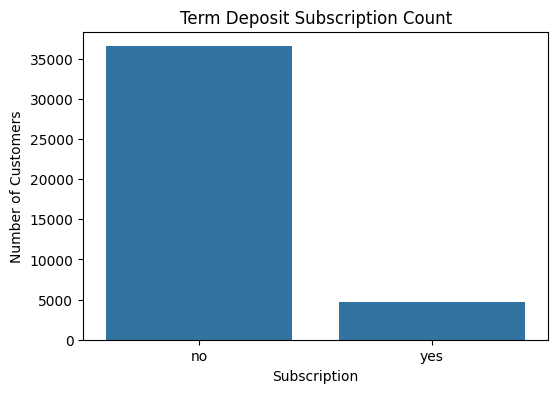

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x='y', data=df)

plt.title('Term Deposit Subscription Count')
plt.xlabel('Subscription')
plt.ylabel('Number of Customers')

plt.show()

#**EDA**

# **Age Distribution**

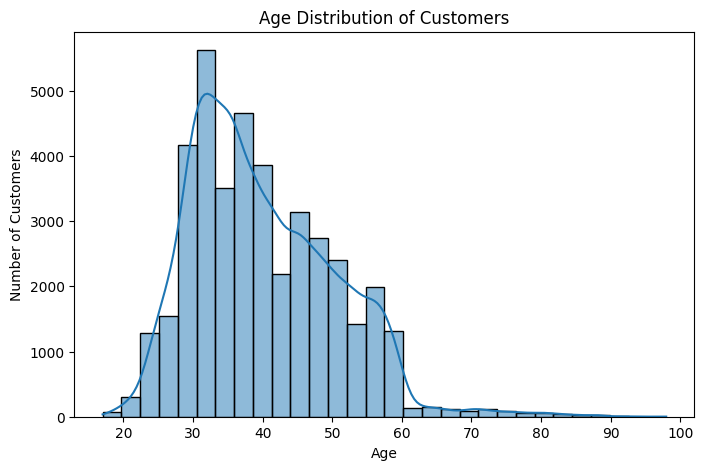

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=30, kde=True)

plt.title('Age Distribution of Customers')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

# **Customer Distribution by Job**

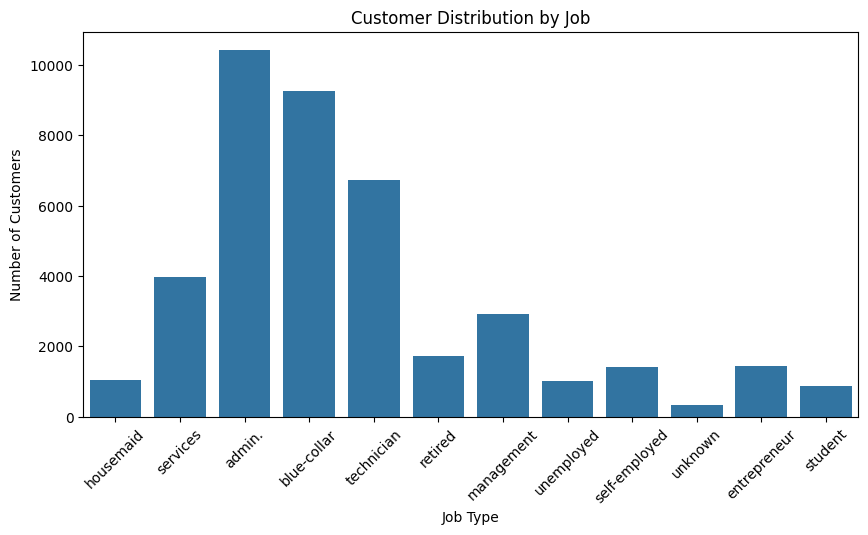

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(x='job', data=df)

plt.title('Customer Distribution by Job')
plt.xlabel('Job Type')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.show()

# **Customer Distribution by Education**

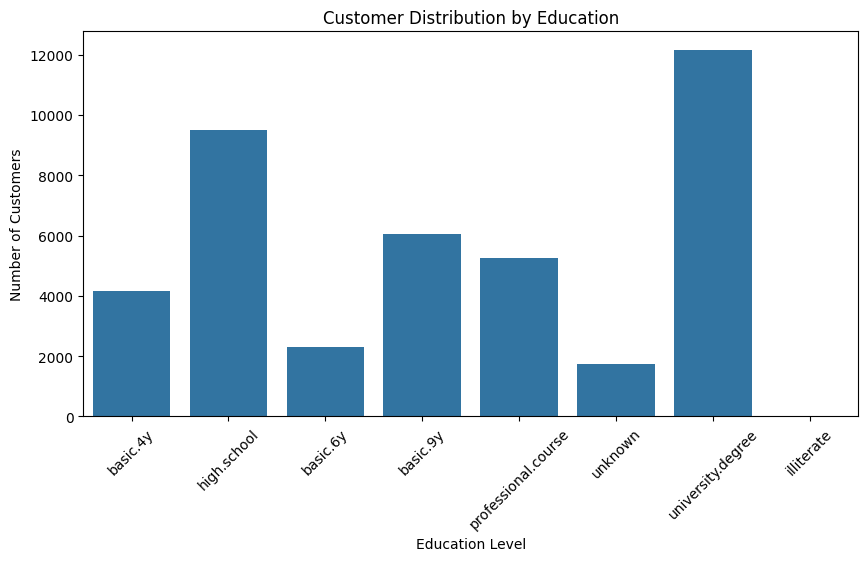

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(x='education', data=df)

plt.title('Customer Distribution by Education')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)

plt.show()

# **Customer Distribution by Marital Status**

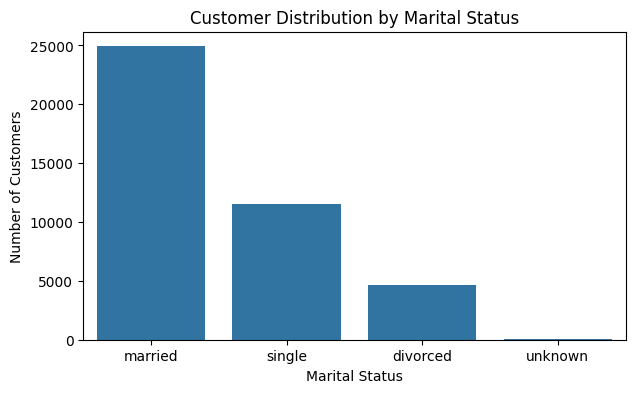

In [ ]:
plt.figure(figsize=(7,4))

sns.countplot(x='marital', data=df)

plt.title('Customer Distribution by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')

plt.show()

# **Customer Distribution by Contact Type**

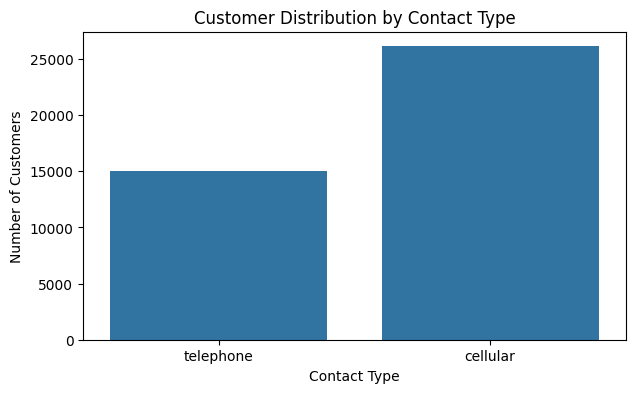

In [ ]:
plt.figure(figsize=(7,4))

sns.countplot(x='contact', data=df)

plt.title('Customer Distribution by Contact Type')
plt.xlabel('Contact Type')
plt.ylabel('Number of Customers')

plt.show()

# **Customer Distribution by Campaign Month**

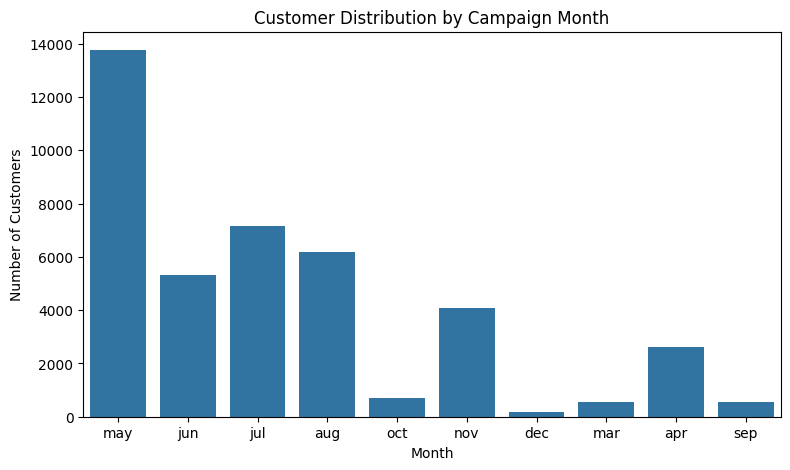

In [ ]:
plt.figure(figsize=(9,5))

sns.countplot(x='month', data=df)

plt.title('Customer Distribution by Campaign Month')
plt.xlabel('Month')
plt.ylabel('Number of Customers')

plt.show()

# **Customer Distribution by Day of Week**

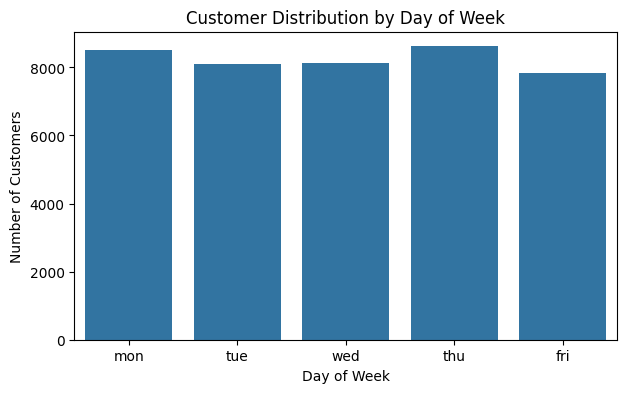

In [ ]:
plt.figure(figsize=(7,4))

sns.countplot(x='day_of_week', data=df)

plt.title('Customer Distribution by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Customers')

plt.show()

# **Subscription by Job Type**

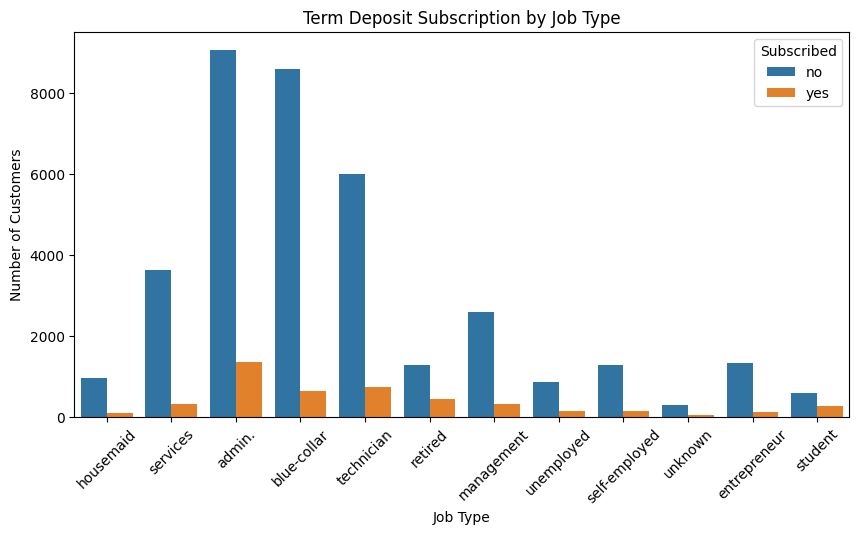

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(x='job', hue='y', data=df)

plt.title('Term Deposit Subscription by Job Type')
plt.xlabel('Job Type')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)
plt.legend(title='Subscribed')

plt.show()

# **Subscription by Education Level**

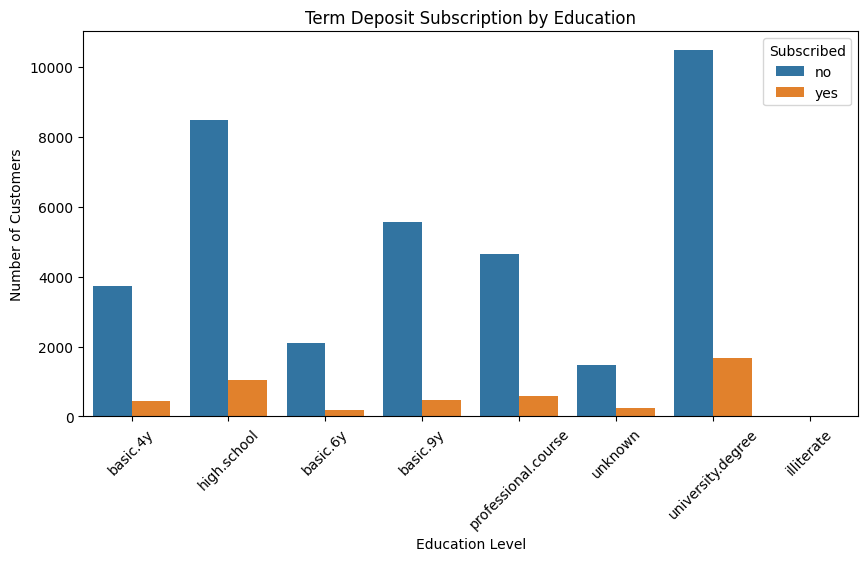

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(x='education', hue='y', data=df)

plt.title('Term Deposit Subscription by Education')
plt.xlabel('Education Level')
plt.ylabel('Number of Customers')

plt.xticks(rotation=45)
plt.legend(title='Subscribed')

plt.show()

# **Subscription by Marital Status**

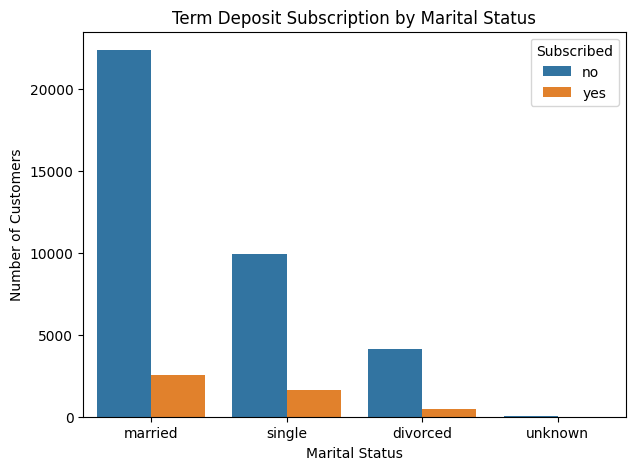

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(x='marital', hue='y', data=df)

plt.title('Term Deposit Subscription by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')

plt.show()

# **Subscription by Contact Type**

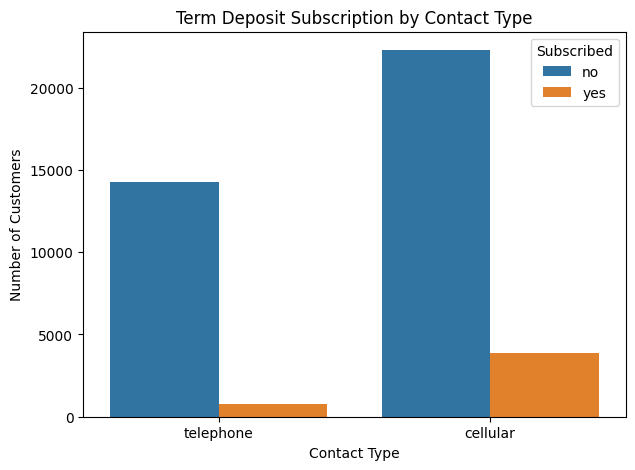

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(x='contact', hue='y', data=df)

plt.title('Term Deposit Subscription by Contact Type')
plt.xlabel('Contact Type')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')

plt.show()

# **Subscription by Campaign Month**

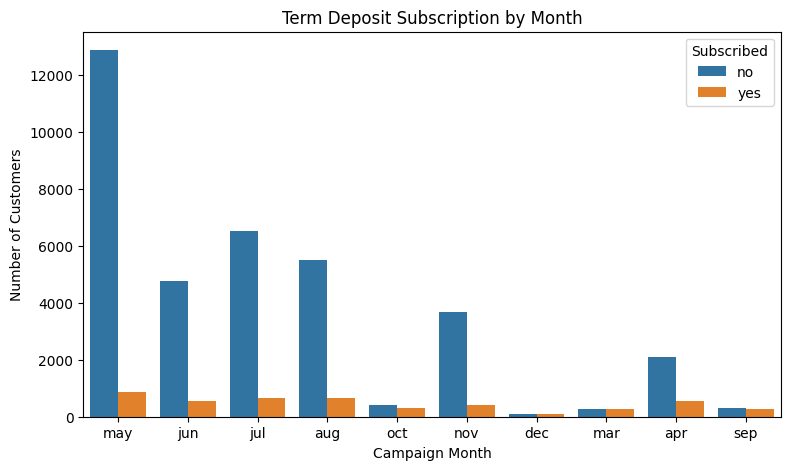

In [ ]:
plt.figure(figsize=(9,5))

sns.countplot(x='month', hue='y', data=df)

plt.title('Term Deposit Subscription by Month')
plt.xlabel('Campaign Month')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')

plt.show()

**Subscription by Day of Week**

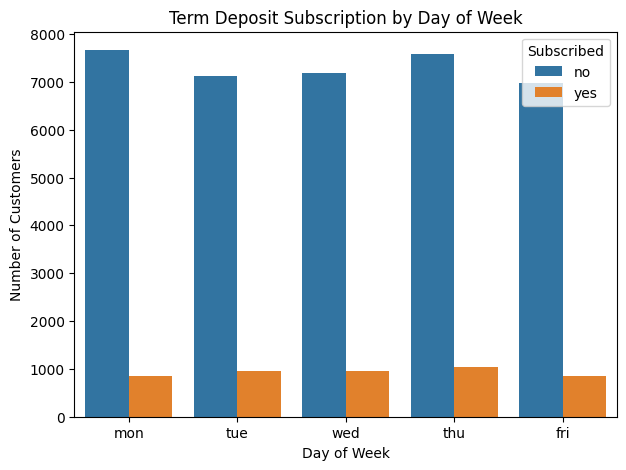

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(x='day_of_week', hue='y', data=df)

plt.title('Term Deposit Subscription by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')

plt.show()

**Campaign Contacts by Subscription**

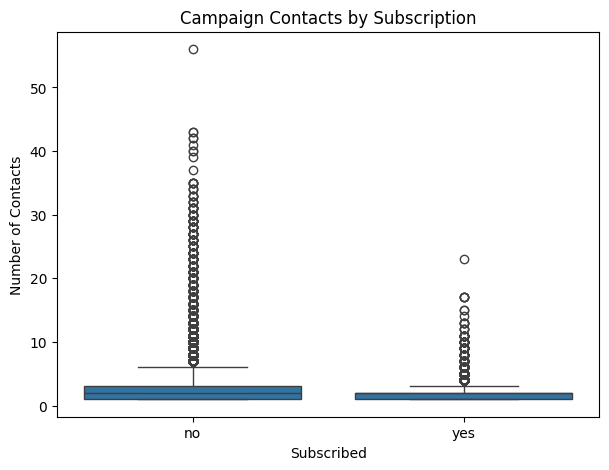

In [ ]:
plt.figure(figsize=(7,5))

sns.boxplot(x='y', y='campaign', data=df)

plt.title('Campaign Contacts by Subscription')
plt.xlabel('Subscribed')
plt.ylabel('Number of Contacts')

plt.show()

**Subscription by Previous Campaign Outcome**

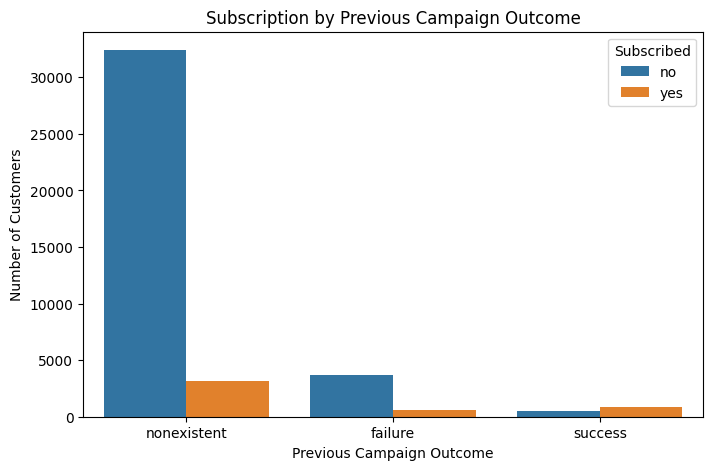

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(x='poutcome', hue='y', data=df)

plt.title('Subscription by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')

plt.show()

**Previous Campaign Contacts**

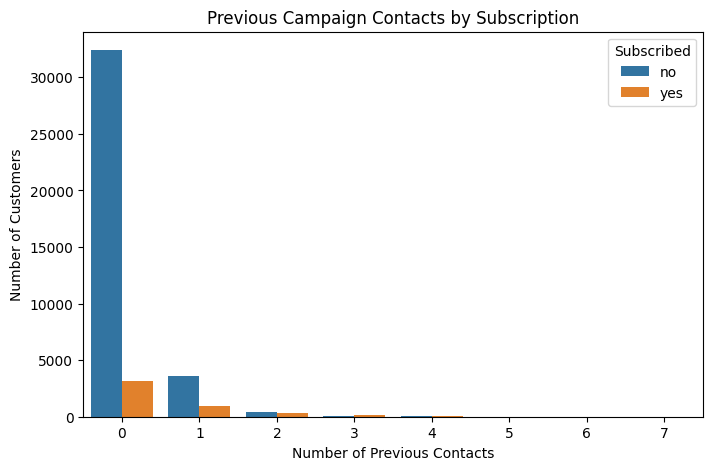

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(x='previous', hue='y', data=df)

plt.title('Previous Campaign Contacts by Subscription')
plt.xlabel('Number of Previous Contacts')
plt.ylabel('Number of Customers')

plt.legend(title='Subscribed')

plt.show()

**Previous Contact Days (pdays)**

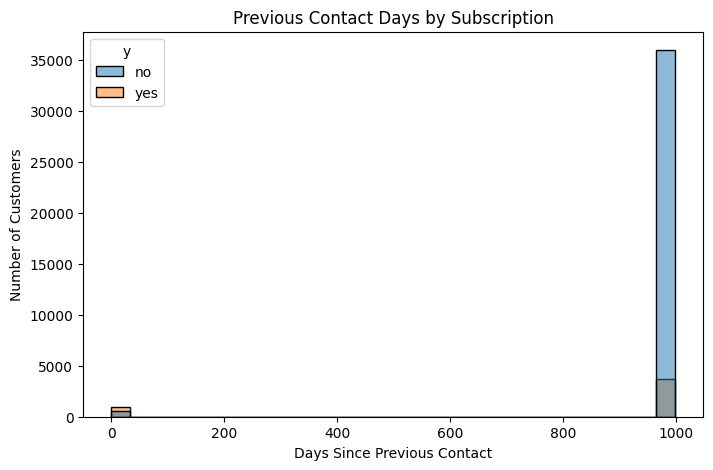

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(data=df, x='pdays', hue='y', bins=30)

plt.title('Previous Contact Days by Subscription')
plt.xlabel('Days Since Previous Contact')
plt.ylabel('Number of Customers')

plt.show()

**Correlation Heatmap**

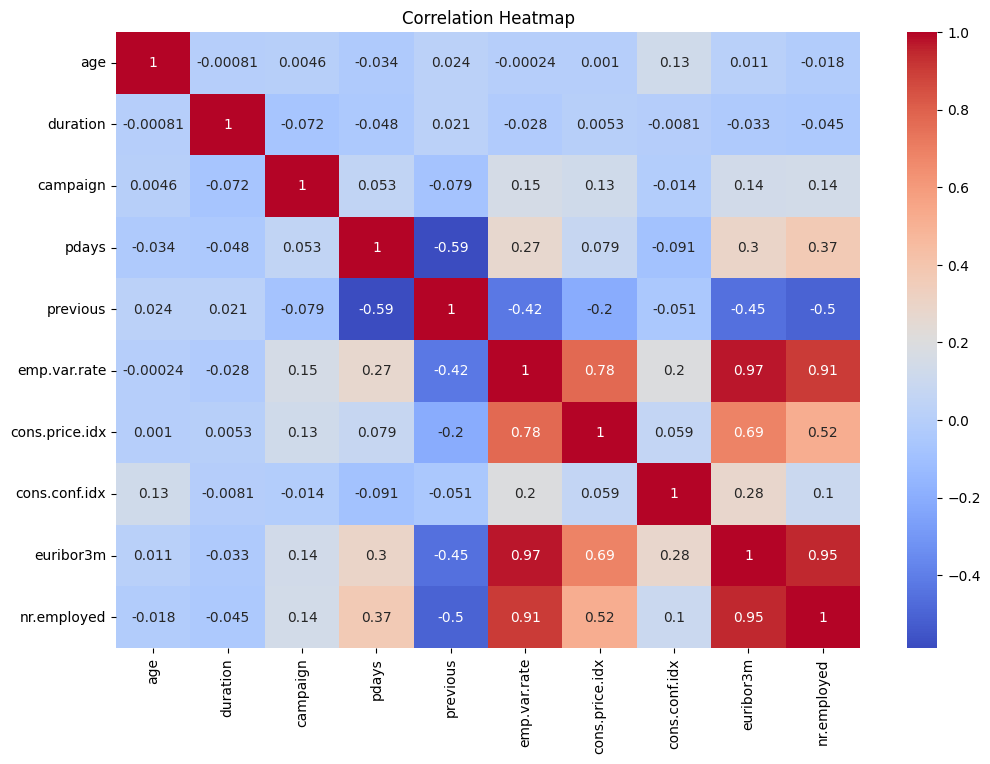

In [ ]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

**Subscription Rate by Job Type**

In [ ]:
job_data = df.groupby('job')['y'].value_counts(normalize=True) * 100

job_data

job            y  
admin.         no     87.033305
               yes    12.966695
blue-collar    no     93.104939
               yes     6.895061
entrepreneur   no     91.483516
               yes     8.516484
housemaid      no     90.000000
               yes    10.000000
management     no     88.782490
               yes    11.217510
retired        no     74.738068
               yes    25.261932
self-employed  no     89.514426
               yes    10.485574
services       no     91.857827
               yes     8.142173
student        no     68.571429
               yes    31.428571
technician     no     89.167532
               yes    10.832468
unemployed     no     85.798817
               yes    14.201183
unknown        no     88.787879
               yes    11.212121
Name: proportion, dtype: float64

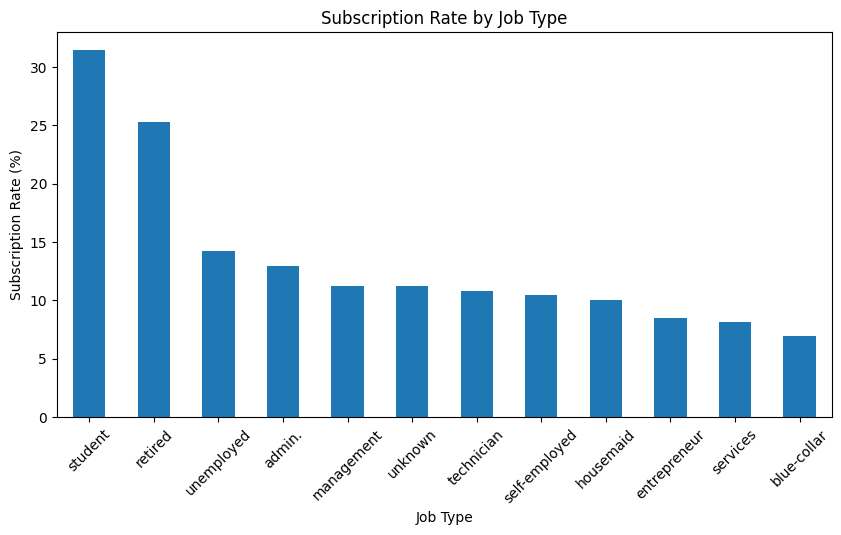

In [ ]:
subscription_rate = pd.crosstab(df['job'], df['y'], normalize='index') * 100

plt.figure(figsize=(10,5))

subscription_rate['yes'].sort_values(ascending=False).plot(kind='bar')

plt.title('Subscription Rate by Job Type')
plt.xlabel('Job Type')
plt.ylabel('Subscription Rate (%)')

plt.xticks(rotation=45)
plt.show()


# **Data Preprocessing.**

In [ ]:
x = df.drop(['y', 'duration'], axis=1)

y = df['y'].map({'no':0, 'yes':1})

In [ ]:
numerical_columns = x.select_dtypes(include=['int64', 'float64']).columns

categorical_columns = x.select_dtypes(include=['object']).columns





In [ ]:
print("Numerical Columns:",numerical_columns)
print("\nCategorical Columns:",categorical_columns)

Numerical Columns: Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')

Categorical Columns: Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object')


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_columns)
    ]
)

In [ ]:
preprocessor

ColumnTransformer(transformers=[('num', StandardScaler(),
                                 Index(['age', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome'],
      dtype='object'))])

**Split Training and Testing Data**

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

# **Encoding and Scaling**

In [ ]:
x_train = preprocessor.fit_transform(x_train)

x_test = preprocessor.transform(x_test)

# **Model Building**

**Logistic Regression Model**

In [ ]:
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000)

lr_model.fit(x_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [ ]:
lr_pred = lr_model.predict(x_test)

In [ ]:
lr_accuracy = accuracy_score(y_test, lr_pred)

print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.8224866440019427


In [ ]:
print(classification_report(y_test, lr_pred))

              precision    recall  f1-score   support

           0       0.94      0.85      0.89      7265
           1       0.36      0.63      0.46       971

    accuracy                           0.82      8236
   macro avg       0.65      0.74      0.67      8236
weighted avg       0.88      0.82      0.84      8236



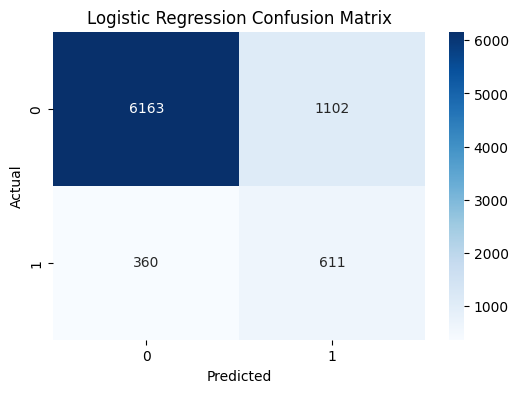

In [ ]:
lr_cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6,4))
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues')

plt.title('Logistic Regression Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
lr_prob = lr_model.predict_proba(x_test)[:, 1]

lr_roc_auc = roc_auc_score(y_test, lr_prob)

print("Logistic Regression ROC-AUC Score:", lr_roc_auc)

Logistic Regression ROC-AUC Score: 0.7920581941691008


**DecisionTreeClassifier**

In [ ]:
dt_model = DecisionTreeClassifier(class_weight='balanced', random_state=42)

dt_model.fit(x_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

In [ ]:
dt_pred = dt_model.predict(x_test)

In [ ]:
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.8397280233122875


In [ ]:
print(classification_report(y_test, dt_pred))

              precision    recall  f1-score   support

           0       0.91      0.91      0.91      7265
           1       0.32      0.33      0.33       971

    accuracy                           0.84      8236
   macro avg       0.62      0.62      0.62      8236
weighted avg       0.84      0.84      0.84      8236



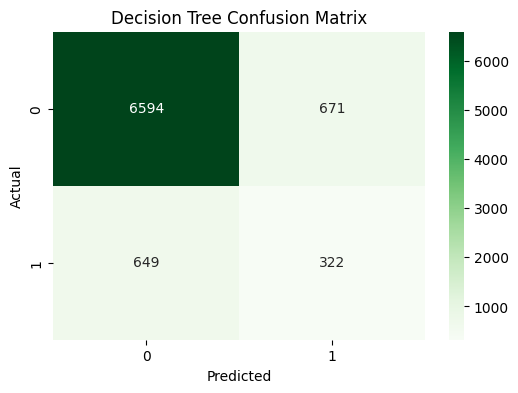

In [ ]:
dt_cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(6,4))
sns.heatmap(dt_cm, annot=True, fmt='d', cmap='Greens')

plt.title('Decision Tree Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [ ]:
dt_prob = dt_model.predict_proba(x_test)[:, 1]

dt_roc_auc = roc_auc_score(y_test, dt_prob)

print("Decision Tree ROC-AUC Score:", dt_roc_auc)

Decision Tree ROC-AUC Score: 0.6200518406110302


**RandomForest**

Random Forest Accuracy: 0.8882952889752307

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7265
           1       0.55      0.28      0.37       971

    accuracy                           0.89      8236
   macro avg       0.73      0.62      0.65      8236
weighted avg       0.87      0.89      0.87      8236



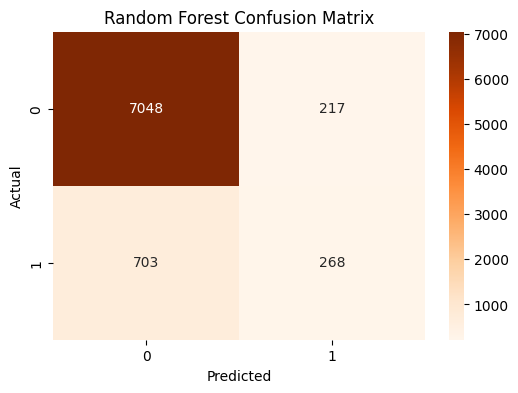

Random Forest ROC-AUC Score: 0.7706878697648177


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42
)

rf_model.fit(x_train, y_train)

rf_pred = rf_model.predict(x_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

rf_cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,4))
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Oranges')
plt.title('Random Forest Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

rf_prob = rf_model.predict_proba(x_test)[:, 1]
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest ROC-AUC Score:", rf_roc_auc)

**GradientBoosting**

Gradient Boosting Accuracy: 0.8971588149587179

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7265
           1       0.68      0.24      0.36       971

    accuracy                           0.90      8236
   macro avg       0.79      0.61      0.65      8236
weighted avg       0.88      0.90      0.87      8236



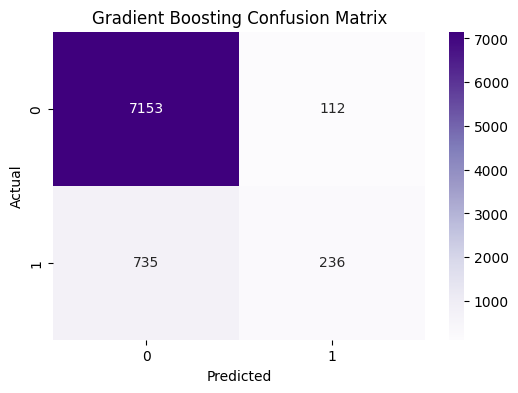

Gradient Boosting ROC-AUC Score: 0.7988754400675331


In [ ]:
gb_model = GradientBoostingClassifier(random_state=42)

gb_model.fit(x_train, y_train)

gb_pred = gb_model.predict(x_test)

gb_accuracy = accuracy_score(y_test, gb_pred)

print("Gradient Boosting Accuracy:", gb_accuracy)
print("\nClassification Report:")
print(classification_report(y_test, gb_pred))

gb_cm = confusion_matrix(y_test, gb_pred)

plt.figure(figsize=(6,4))
sns.heatmap(gb_cm, annot=True, fmt='d', cmap='Purples')
plt.title('Gradient Boosting Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

gb_prob = gb_model.predict_proba(x_test)[:, 1]
gb_roc_auc = roc_auc_score(y_test, gb_prob)

print("Gradient Boosting ROC-AUC Score:", gb_roc_auc)

**model_comparison**

In [ ]:
model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred)
    ],
    'Precision': [
        precision_score(y_test, lr_pred),
        precision_score(y_test, dt_pred),
        precision_score(y_test, rf_pred),
        precision_score(y_test, gb_pred)
    ],
    'Recall': [
        recall_score(y_test, lr_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, gb_pred)
    ],
    'F1 Score': [
        f1_score(y_test, lr_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, gb_pred)
    ],
    'ROC-AUC': [
        lr_roc_auc, dt_roc_auc, rf_roc_auc, gb_roc_auc
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.822487,0.356684,0.629248,0.455291,0.792058
1,Decision Tree,0.839728,0.324270,0.331617,0.327902,0.620052
2,Random Forest,0.888295,0.552577,0.276004,0.368132,0.770688
3,Gradient Boosting,0.897159,0.678161,0.243048,0.357847,0.798875


In [ ]:
best_model = model_comparison.sort_values(by='F1 Score', ascending=False)

print(best_model)

print("\nBest Performing Model:")
print(best_model.iloc[0]['Model'])

                 Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0  Logistic Regression  0.822487   0.356684  0.629248  0.455291  0.792058
2        Random Forest  0.888295   0.552577  0.276004  0.368132  0.770688
3    Gradient Boosting  0.897159   0.678161  0.243048  0.357847  0.798875
1        Decision Tree  0.839728   0.324270  0.331617  0.327902  0.620052

Best Performing Model:
Logistic Regression


In [ ]:
print("Logistic Regression:", lr_f1)
print("Decision Tree:", dt_f1)
print("Random Forest:", rf_f1)
print("Gradient Boosting:", gb_f1)

NameError: name 'lr_f1' is not defined

In [ ]:
lr_f1 = f1_score(y_test, lr_pred)
dt_f1 = f1_score(y_test, dt_pred)
rf_f1 = f1_score(y_test, rf_pred)
gb_f1 = f1_score(y_test, gb_pred)

In [ ]:
print("Logistic Regression:", lr_f1)
print("Decision Tree:", dt_f1)
print("Random Forest:", rf_f1)
print("Gradient Boosting:", gb_f1)

Logistic Regression: 0.455290611028316
Decision Tree: 0.32790224032586557
Random Forest: 0.36813186813186816
Gradient Boosting: 0.35784685367702807


In [ ]:
print("Logistic Regression:", lr_accuracy)
print("Decision Tree:", dt_accuracy)
print("Random Forest:", rf_accuracy)
print("Gradient Boosting:", gb_accuracy)

Logistic Regression: 0.8224866440019427
Decision Tree: 0.8397280233122875
Random Forest: 0.8882952889752307
Gradient Boosting: 0.8971588149587179


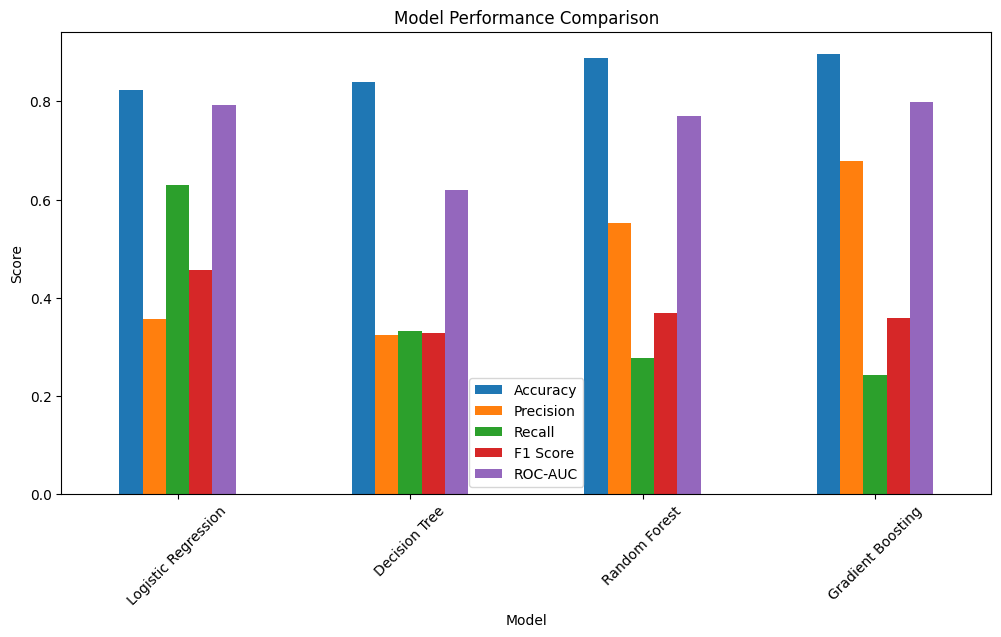

In [ ]:
model_comparison.plot(
    x='Model',
    y=['Accuracy', 'Precision', 'Recall', 'F1 Score', 'ROC-AUC'],
    kind='bar',
    figsize=(12,6)
)
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.show()

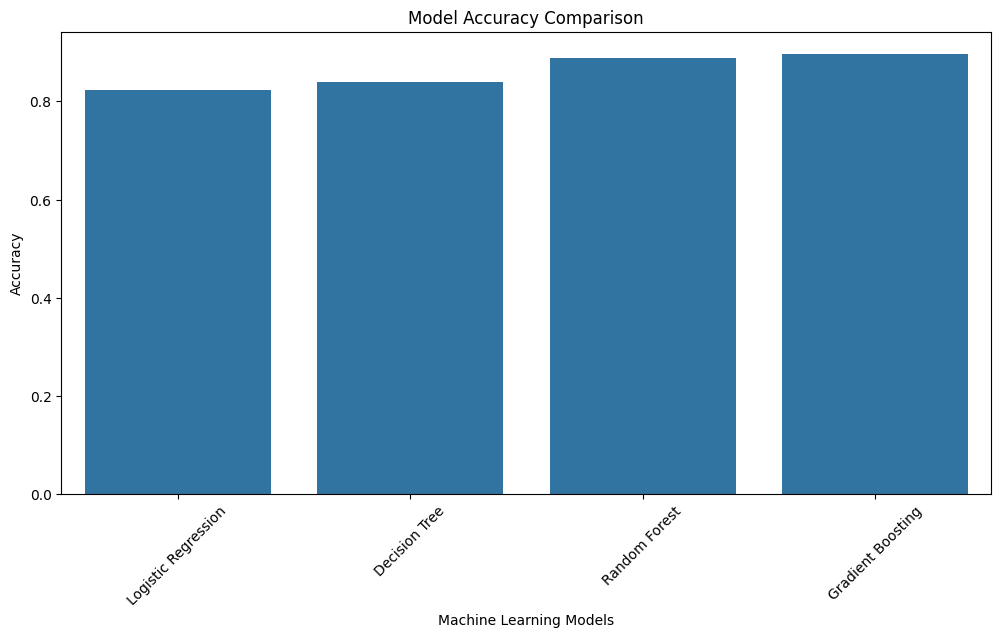

In [ ]:
plt.figure(figsize=(12,6))

sns.barplot(data=model_comparison, x='Model', y='Accuracy')

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')
plt.xticks(rotation=45)
plt.show()

In [ ]:
import pickle

with open('bank_model.pkl', 'wb') as file:
    pickle.dump(rf_model, file)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
with open('bank_model.pkl', 'rb') as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


## Business Recommendations

1. Target customers from job, age, and education groups that show higher subscription rates.

2. Focus on campaign months and days that generate better customer responses.

3. Avoid contacting customers too frequently, as repeated calls may reduce customer interest.

4. Give priority to customers who showed positive responses in previous campaigns.

5. Use customer data to identify potential subscribers and improve marketing strategies.

6. Use machine learning models to predict customers who are more likely to subscribe.

## Conclusion

The Portuguese Bank Marketing dataset was analyzed to understand customer behavior and term deposit subscriptions.

Exploratory Data Analysis was performed to identify patterns and relationships in customer data.

Four machine learning classification models were developed:
- Logistic Regression
- Decision Tree
- Random Forest
- Gradient Boosting

The models were evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

The model comparison helps identify a suitable model for predicting customer subscriptions.

This project demonstrates how data analysis and machine learning can help banks improve marketing campaigns and identify potential customers.